# One wedge, two radiographs: X-rays and neutrons

**Author:** Damian Martín Rodríguez  
**Software:** gVXR 2.1.0 · NCrystal 4.4.6 · Python 3.11  
**License:** [MIT](LICENSE)

Compare direct transmission through the same polyethylene step wedge for 80 keV photons and 1.8 Å neutrons. NCrystal supplies the neutron attenuation coefficient; gVXR projects both beams through the same geometry. The [sample mesh](polyethylene_step_wedge.stl) is included; no experimental dataset is required.

Keep the STL beside this notebook, select the Python kernel from the **gvxr-wedge** environment, and run the cells in order.


## 1. Import the modules
NCrystal describes the material. gVXR places the source, sample and detector and calculates the images. NumPy and Matplotlib handle the arrays and plots.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import NCrystal as NC
from gvxrPython3 import gvxr

## 2. Define the circular aperture
Place a 30 mm opening in the xy plane at z = 0. To represent uniform illumination, we will project from 258 equally weighted positions across the disk. The square root spaces the points uniformly **in area**; pairing each point with its opposite keeps the source centred.

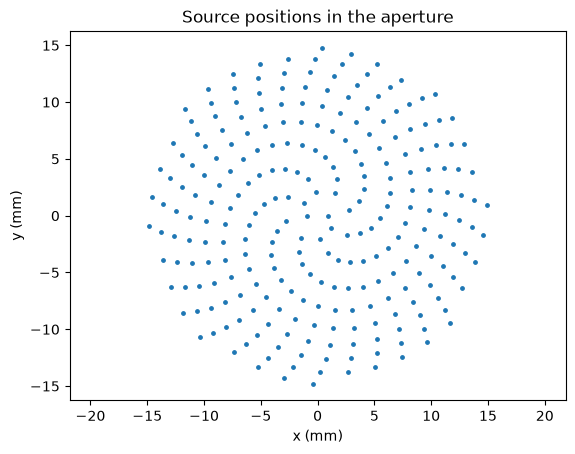

In [2]:
diameter_mm = 30
n_points = 258  # choose an even number
assert n_points >= 4 and n_points % 2 == 0
k = np.arange(n_points // 2)
radius = (diameter_mm / 2) * np.sqrt((k + 0.5) / len(k))
angle = k * np.pi * (3 - np.sqrt(5))
half = np.column_stack((radius * np.cos(angle), radius * np.sin(angle)))
aperture = np.vstack((half, -half))

plt.scatter(*aperture.T, s=6)
plt.axis("equal")
plt.xlabel("x (mm)"); plt.ylabel("y (mm)")
plt.title("Source positions in the aperture"); plt.show()

## 3. Choose the two beams and the material
Use the benchmark settings: monochromatic **80 keV X-rays** (0.155 Å) and **1.8 Å neutrons**. These are different wavelengths, chosen for their respective imaging regimes. To change the comparison, edit the two inputs below. Both calculations use CH₂ at the density reported by the same NCrystal material.

In [ ]:
xray_keV = 80.0
neutron_A = 1.8
material = "Polyethylene_CH2.ncmat"
info = NC.createInfo(material)
density = float(info.density)
print(f"X-rays: {12.39842/xray_keV:.4f} Å; neutrons: {neutron_A:g} Å; density: {density:g} g/cm³")

**Neutron attenuation.** Multiply the total microscopic cross section (barn/atom) by number density (atoms/Å³) to get cm⁻¹. Scattering removes neutrons from the direct beam. For X-rays, we will let gVXR calculate the coefficient from composition, density and photon energy after loading the wedge.

In [ ]:
scatter = NC.createScatter(material).xsect(wl=neutron_A)
absorption = NC.createAbsorption(material).xsect(wl=neutron_A)
mu_n = float(info.numberdensity * (scatter + absorption))
print(f"Neutron linear attenuation: {mu_n:.4f} cm⁻¹")

## 4. Build the shared instrument
**4a · Geometry.** The beam travels along +z. The 30 mm aperture is at z = 0. L/D is measured to the downstream face of the wedge.

In [ ]:
mesh = Path("polyethylene_step_wedge.stl")
assert mesh.is_file(), "Put the wedge STL beside this notebook."
L = 100 * diameter_mm        # mm, aperture to rear face
detector_z = L + 10          # 10 mm sample–detector gap
pixels = 512
fov_mm = 150
pitch = fov_mm / pixels

**4b · OpenGL and source.** Open a visible window. Start at the aperture centre so we can inspect the instrument before moving the source. The energy bin is physical for X-rays; for neutrons it only initializes gVXR’s count calculation.

In [ ]:
gvxr.createWindow(-1, 1, "OPENGL", 4, 3)
gvxr.setSourcePosition(0, 0, 0, "mm")
gvxr.usePointSource()
gvxr.setMonoChromaticPerPixelAtSDD(xray_keV, "keV", 10000)

**4c · Detector.** Place the ideal detector downstream, set its pixel pitch and save its orientation. Moving the source later must not tilt the detector.

In [ ]:
gvxr.setDetectorPosition(0, 0, detector_z, "mm")
gvxr.setDetectorUpVector(0, 1, 0)
gvxr.setDetectorNumberOfPixels(pixels, pixels)
gvxr.setDetectorPixelSize(pitch, pitch, "mm")
up = tuple(gvxr.getDetectorUpVector())
right = tuple(gvxr.getDetectorRightVector())

**4d · Sample and X-ray attenuation.** The STL describes only the surface. Its rear face is already at local z = 0; translate it without recentering. Assign polyethylene to the wedge and read the photon coefficient at the chosen energy.

In [ ]:
gvxr.loadMeshFile("wedge", str(mesh.resolve()), "mm")
gvxr.translateNode("wedge", 0, 0, L, "mm")
gvxr.setCompound("wedge", "CH2")
gvxr.setDensity("wedge", density, "g/cm3")
mu_x = gvxr.getLinearAttenuationCoefficient("wedge", xray_keV, "keV")
print(f"Linear attenuation (cm⁻¹): X-rays {mu_x:.4f}, neutrons {mu_n:.4f}")

## 5. Inspect the instrument in OpenGL
Render one central-source preview. The screenshot below shows the same geometry used for both modalities. The single source marker shows the current position; the disk in Part 2 is represented by successive source positions during exposure.

In [ ]:
gvxr.setColour("wedge", 0.15, 0.62, 0.78, 1.0)
gvxr.computeXRayImage(False)
gvxr.displayScene()
plt.figure(figsize=(9, 5))
plt.imshow(np.asarray(gvxr.takeScreenshot()))
plt.title("OpenGL view: aperture centre, wedge and detector")
plt.axis("off")
plt.show()

**Explore the live scene.** The next cell opens the interactive view. Right-drag to rotate, scroll to zoom, and press **Q or Escape in the OpenGL window** to resume the notebook. Skip this cell if you only want the screenshot.

In [ ]:
gvxr.renderLoop()

## 6. Acquire the two radiographs
**6a · One exposure.** Use the same function for each beam. Each aperture position contributes equally to the mean count image. The detector remains fixed. Count mode avoids weighting counts by the placeholder photon energy in the neutron case.

In [ ]:
def exposure():
    counts = np.zeros((pixels, pixels))
    for x, y in aperture:
        gvxr.setSourcePosition(float(x), float(y), 0, "mm")
        gvxr.setDetectorPosition(0, 0, detector_z, "mm")
        gvxr.setDetectorUpVector(*up)
        gvxr.setDetectorRightVector(*right)
        frame = np.asarray(gvxr.computeXRayImage(False))
        if frame.shape != counts.shape or not np.isfinite(frame).all():
            raise RuntimeError("Invalid gVXR frame; check the OpenGL context.")
        counts += frame
    return counts / len(aperture)

**6b · X-ray acquisition.** Use the compound and density so the renderer evaluates photon attenuation.

In [ ]:
gvxr.setCompound("wedge", "CH2")
gvxr.setDensity("wedge", density, "g/cm3")
xray_counts = exposure()

**6c · Neutron acquisition.** Keep everything in place and replace only the material coefficient with the NCrystal result.

In [ ]:
gvxr.setLinearAttenuationCoefficient("wedge", mu_n, "cm-1")
neutron_counts = exposure()

**6d · Open beam.** Make the wedge transparent. A shared flat is appropriate here because both exposures use the same ideal count detector, aperture weights and nominal incident counts. This models normalized transmission, not two instruments’ absolute fluxes.

In [ ]:
gvxr.setLinearAttenuationCoefficient("wedge", 0.0, "cm-1")
flat = exposure()
assert np.all(flat > 0), "Cannot normalize: the open beam contains empty pixels."
T_x = xray_counts / flat
T_n = neutron_counts / flat
gvxr.destroy()  # images stay in Python; rerun from 4b to rebuild the scene

## 7. Compare the radiographs
Both panels use the same detector coordinates and grayscale: white is full transmission, black is zero. Zooming to the wedge keeps the steps visible. Compare the same step across the two panels; the darker image transmits less of the incident beam. Neither model adds scattered particles back into the detector.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True,
                         constrained_layout=True)
h = fov_mm / 2
for ax, image, title in zip(axes, (T_x, T_n),
                            (f"X-rays · {xray_keV:g} keV", f"Neutrons · {neutron_A:g} Å")):
    im = ax.imshow(image, origin="lower", extent=(-h,h,-h,h), vmin=0, vmax=1,
                   cmap="gray", interpolation="nearest")
    ax.set(title=title, xlabel="Detector horizontal position (mm)", xlim=(-35,35), ylim=(-23,23))
axes[0].set_ylabel("Detector vertical position (mm)")
fig.colorbar(im, ax=axes, label="Direct-beam transmission")
plt.show()